[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beykyle/jitr/blob/main/examples/notebooks/comparison_to_Runge_Kutta.ipynb)

In [1]:
# Google Colab setup: installs jitr into the Colab runtime.
# Does nothing when the notebook is run anywhere else.
import sys

if "google.colab" in sys.modules:
    import subprocess

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "jitr"],
        check=True,
    )

Let's compare `jitr` to a standard Runge-Kutta ODE solver, the 8th-order `DOP853` method of `scipy.integrate.solve_ivp`, first for one partial wave at one energy, then for a whole grid of energies.

In [2]:
import time

import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import solve_ivp

from jitr.optical_potentials.potential_forms import woods_saxon_potential
from jitr.reactions import Level
from jitr.utils import radial_equation
from jitr.utils.free_solutions import coulomb_hankel_table
from jitr.utils.kinematics import classical_kinematics, level_kinematics
from jitr.xs import coupled

First let's check our library versions and configs, as this will affect performance:

In [3]:
import scipy as sc

sc.__version__

'1.17.1'

In [4]:
import jax

jax.__version__

'0.11.2'

In [5]:
np.__version__

'2.4.4'

In [6]:
# np.show_config()

Great, now let's set up our system with `jitr`: a neutron on $^{44}$Ca at 42.1 MeV. A `coupled.Workspace` with a single spin-0 level is the simplest scattering problem: each $J^\pi$ block holds one channel, the partial wave $l = J$. The workspace takes the channel radius in fm, the number of Lagrange-Legendre basis functions, and the squared wavenumber, reduced mass and Sommerfeld parameter of each level from `level_kinematics`.

In [7]:
mass_target, mass_projectile, Zz = 44657, 938.3, 0
Elab = 42.1
kin = classical_kinematics(mass_target, mass_projectile, Elab, Zz)
k2, mu, eta = level_kinematics(kin, [0.0])

channel_radius = 10 * np.pi / kin.k  # five wavelengths, in fm
nbasis = 40
lmax = 10
ws = coupled.Workspace(channel_radius, nbasis, [Level(0)], lmax, k2, mu, eta)
ws.blocks.l[:, 0]

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [8]:
# Woods-Saxon potential parameters
V0 = -60  # real potential strength
W0 = -20  # imag potential strength
R0 = 4  # Woods-Saxon potential radius
a0 = 0.5  # Woods-Saxon potential diffuseness
params = (V0, W0, R0, a0)


def potential(r):
    return woods_saxon_potential(r, *params)

The interaction is a list of `(coupling, form)` terms; for one channel the coupling is just `np.eye(1)` and the form is the potential on the mesh `ws.r`. One call solves every partial wave. Results are indexed `[energy, block, channel, channel]`:

In [9]:
S, u, _ = ws.wavefunctions(local=[(np.eye(1), potential(ws.r))])
l = 5
S_lm = complex(S[0, l, 0, 0])
print(S_lm)

(-0.04726062228907012-0.27365461463192j)


Great, now let's use `scipy` and see if we get the same $\mathcal{S}$-matrix. We integrate $u'' = [l(l+1)/r^2 + 2\mu V(r)/\hbar^2 - k^2]\, u$ outward from near the origin, where $u \propto r^{l+1}$, to the channel radius $a$, and match $u$ to the outgoing and incoming Coulomb-Hankel functions $H^\pm(\rho)$ at $\rho = ka$:

$$
S = \frac{u'(a) H^-(ka) - k u(a) H^{-\prime}(ka)}{u'(a) H^+(ka) - k u(a) H^{+\prime}(ka)}.
$$

In [10]:
def runge_kutta(l, k, mu, eta, a, r0=1e-3, tol=1e-9):
    # u = r0, u' = (l + 1) at r0 has the logarithmic derivative of r^(l + 1);
    # the overall normalization is arbitrary
    sol = solve_ivp(
        radial_equation,
        (r0, a),
        np.array([r0, l + 1], complex),
        args=(l, k, mu, potential),
        method="DOP853",
        dense_output=True,
        atol=tol,
        rtol=tol,
    ).sol
    u, du = sol(a)
    Hp, Hm, Hpp, Hmp = (h[l] for h in coulomb_hankel_table(k * a, eta, l))
    return (du * Hm - k * u * Hmp) / (du * Hp - k * u * Hpp), sol

### compare S-matrix elements

In [11]:
S_rk, sol_rk = runge_kutta(l, kin.k, kin.mu, kin.eta, channel_radius)
print(S_rk)

(-0.04734023965505159-0.2737167911087751j)


In [12]:
pct_diff = 100 * (S_lm - S_rk) / S_rk
pct_diff

np.complex128(-0.026940535878730014+0.024428041648915072j)

In [13]:
assert np.abs(pct_diff) < 0.1

### compare wavefunctions

`ws.wavefunctions` returns the interior wavefunction at the mesh points `ws.r`. The Runge-Kutta solution has an arbitrary normalization, so we scale it to agree at the last mesh point:

In [14]:
u_lm = np.asarray(u[0, l, 0, 0])
u_rk = sol_rk(ws.r)[0]
normalization = u_lm[-1] / u_rk[-1]
u_rk *= normalization
np.testing.assert_allclose(u_rk, u_lm, rtol=1e-6, atol=1e-3 * np.abs(u_lm).max())

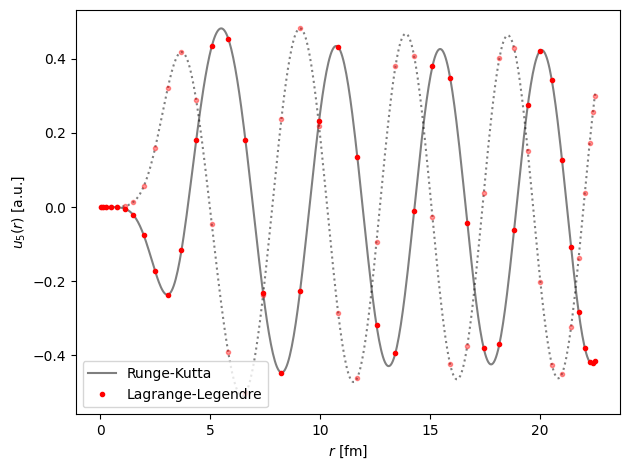

In [15]:
r_fine = np.linspace(1e-3, channel_radius, 500)
u_fine = normalization * sol_rk(r_fine)[0]
plt.plot(r_fine, u_fine.real, "k", alpha=0.5, label="Runge-Kutta")
plt.plot(r_fine, u_fine.imag, ":k", alpha=0.5)
plt.plot(ws.r, u_lm.real, "r.", label="Lagrange-Legendre")
plt.plot(ws.r, u_lm.imag, "r.", alpha=0.4)
plt.xlabel(r"$r$ [fm]")
plt.ylabel(rf"$u_{l}(r)$ [a.u.]")
plt.legend()
plt.tight_layout()
plt.show()

### compare timing
Great, our solvers agree up to high precision. Now let's compare the runtime. The first call of a workspace compiles the solver; every later call with a new potential reuses the compiled code. So build the workspace once and call it as often as you like. Here is one call, solving all 11 partial waves:

In [16]:
%%timeit
S, _ = ws.smatrix(local=[(np.eye(1), potential(ws.r))])
S.block_until_ready()

1.6 ms ± 531 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


and here is the Runge-Kutta solution of the same 11 partial waves:

In [17]:
%%timeit -r 3
for l in range(lmax + 1):
    runge_kutta(l, kin.k, kin.mu, kin.eta, channel_radius)

1.67 s ± 219 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


On my machine the workspace is about a thousand times faster. (This does, of course, depend on the solver parameters: `atol` and `rtol` for `solve_ivp`, and `nbasis` for the workspace.)

### accuracy over a range of energies

A workspace takes any number of energies at once: pass arrays to the kinematics and every energy and partial wave is solved in one call. The mesh is shared by all energies, so we fix the channel radius in fm, well outside the potential, and choose `nbasis` for the largest wavenumber. Let's see how the agreement with Runge-Kutta depends on energy and on `nbasis`, for a few partial waves:

In [18]:
energies = np.linspace(2, 100, 20)
kin_grid = classical_kinematics(mass_target, mass_projectile, energies, Zz)
k2_grid, mu_grid, eta_grid = level_kinematics(kin_grid, [0.0])
radius = 12.0  # fm

partial_waves = [0, 3, 6]
start = time.perf_counter()
S_rk = np.array(
    [
        [
            runge_kutta(l, kin_grid.k[e], kin_grid.mu, 0.0, radius)[0]
            for l in partial_waves
        ]
        for e in range(energies.size)
    ]
)
print(f"Runge-Kutta: {time.perf_counter() - start:.1f} s for {S_rk.size} solves")

Runge-Kutta: 4.9 s for 60 solves


nbasis = 30: 17.6 ms for 220 solves


nbasis = 40: 35.6 ms for 220 solves


nbasis = 60: 75.1 ms for 220 solves


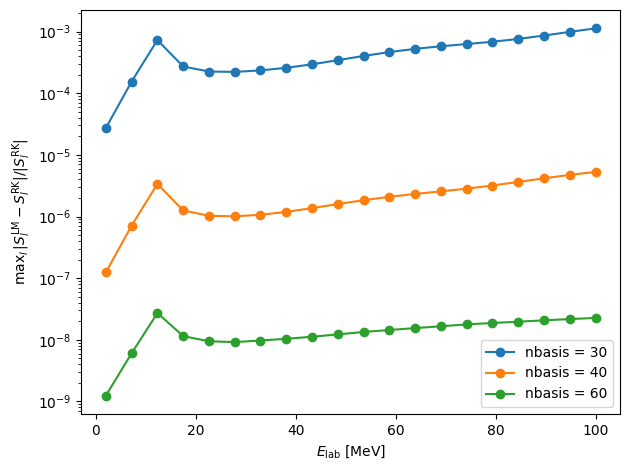

In [19]:
for nbasis_grid in (30, 40, 60):
    ws_grid = coupled.Workspace(
        radius, nbasis_grid, [Level(0)], lmax, k2_grid, mu_grid, eta_grid
    )
    S, _ = ws_grid.smatrix(local=[(np.eye(1), potential(ws_grid.r))])  # compiles
    start = time.perf_counter()
    S, _ = ws_grid.smatrix(local=[(np.eye(1), potential(ws_grid.r))])
    S.block_until_ready()
    elapsed = time.perf_counter() - start
    print(
        f"nbasis = {nbasis_grid}: {1e3 * elapsed:.1f} ms for {S.shape[0] * S.shape[1]} solves"
    )
    S_lm = np.asarray(S[:, partial_waves, 0, 0])
    error = np.abs(S_lm - S_rk) / np.abs(S_rk)
    plt.semilogy(energies, error.max(axis=1), "o-", label=f"nbasis = {nbasis_grid}")

plt.xlabel(r"$E_{\rm lab}$ [MeV]")
plt.ylabel(r"max$_l\, |S^{\rm LM}_l - S^{\rm RK}_l| / |S^{\rm RK}_l|$")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
assert error.max() < 1e-6

The error grows with energy, as the wavelength shrinks relative to the mesh spacing, and falls exponentially with `nbasis` until it reaches the tolerance of the Runge-Kutta integration. With 60 basis functions on 12 fm the two methods agree to about $10^{-8}$ up to 100 MeV, while `jitr` solves all 220 energies and partial waves in a fraction of the time Runge-Kutta needs for one partial wave at each energy.